# 03 — Modelagem

O notebook executa split estratificado, validação cruzada de **três classificadores distintos** e persiste a pipeline selecionada. O teste permanece reservado para o notebook 04.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from src.config import RANDOM_STATE, FIGURES, METRICS, MODELS, TARGET

FIGURES.mkdir(parents=True, exist_ok=True)
METRICS.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
print("RANDOM_STATE =", RANDOM_STATE)

import joblib
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, make_scorer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from src.config import TEST_SIZE, CV_FOLDS
from src.data import load_processed
from src.models import get_models
from src.evaluation import save_metrics

RANDOM_STATE = 42


In [2]:
df=load_processed(); display(df.head()); print("Dimensão:",df.shape)

,ID,AMT_INCOME_TOTAL,AGE_YEARS,EMPLOYMENT_YEARS,CNT_CHILDREN,CNT_FAM_MEMBERS,FLAG_OWN_CAR,FLAG_OWN_REALTY,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,FLAG_EMPLOYMENT_SENTINEL,FLAG_FAMILY_INCONSISTENT,CODE_GENDER,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,OCCUPATION_TYPE,TARGET_BAD
0,5008804,427500.0,32.867899,12.435318,0,2,1,1,1,0,0,0,0,M,Working,Higher education,Civil marriage,Rented apartment,Unknown,1
1,5008805,427500.0,32.867899,12.435318,0,2,1,1,1,0,0,0,0,M,Working,Higher education,Civil marriage,Rented apartment,Unknown,1
2,5008806,112500.0,58.792608,3.104723,0,2,1,1,0,0,0,0,0,M,Working,Secondary / secondary special,Married,House / apartment,Security staff,0
3,5008808,270000.0,52.320329,8.353183,0,1,0,1,0,1,1,0,0,F,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff,0
4,5008810,270000.0,52.320329,8.353183,0,1,0,1,0,1,1,0,0,F,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,Sales staff,0


Dimensão: (33110, 20)


## 1. Split treino/teste

`stratify` preserva a proporção das classes. O teste é mantido intacto até o notebook 04.

In [3]:
X=df.drop(columns=["ID",TARGET]); y=df[TARGET].astype(int); ids=df["ID"]
X_train,X_test,y_train,y_test,ids_train,ids_test=train_test_split(X,y,ids,test_size=TEST_SIZE,stratify=y,random_state=RANDOM_STATE)
assert X_train.shape==(26488,18); assert X_test.shape==(6622,18); assert (y_train==1).sum()==3433; assert (y_test==1).sum()==858; assert set(ids_train).isdisjoint(set(ids_test))
display(pd.DataFrame({"conjunto":["Treino","Teste"],"clientes":[len(y_train),len(y_test)],"bons":[(y_train==0).sum(),(y_test==0).sum()],"maus":[(y_train==1).sum(),(y_test==1).sum()],"pct_maus":[y_train.mean()*100,y_test.mean()*100]}).round(2))

,conjunto,clientes,bons,maus,pct_maus
0,Treino,26488,23055,3433,12.96
1,Teste,6622,5764,858,12.96


## 2. Modelos candidatos

As pipelines encapsulam imputação, escala/codificação e balanceamento quando aplicável. São comparados KNN, Decision Tree e Random Forest.

In [4]:
modelos=get_models()
print("Classificadores avaliados:")
for nome in modelos: print("-",nome)

Classificadores avaliados:
- KNN — RandomOverSampler
- Decision Tree — RandomOverSampler
- Random Forest — Class Weight


## 3. Validação cruzada

`StratifiedKFold` com 5 folds é usado para comparar os modelos sem tocar no teste. O F1 é a métrica principal de equilíbrio, acompanhado de Precision e Recall.

In [5]:
cv=StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=RANDOM_STATE)
scoring={"accuracy":make_scorer(accuracy_score),"precision":make_scorer(precision_score,zero_division=0),"recall":make_scorer(recall_score,zero_division=0),"f1":make_scorer(f1_score,zero_division=0)}
linhas=[]
for nome,modelo in modelos.items():
    resultado=cross_validate(clone(modelo),X_train,y_train,cv=cv,scoring=scoring,return_train_score=False,n_jobs=1,error_score="raise")
    linhas.append({"Modelo":nome,"Accuracy_%":resultado["test_accuracy"].mean()*100,"Precision_%":resultado["test_precision"].mean()*100,"Recall_%":resultado["test_recall"].mean()*100,"F1_%":resultado["test_f1"].mean()*100,"DP_F1_pp":resultado["test_f1"].std(ddof=0)*100})
resumo_cv=pd.DataFrame(linhas).sort_values("F1_%",ascending=False).reset_index(drop=True)
display(resumo_cv.round(2)); save_metrics(resumo_cv,"validacao_cruzada_modelos.csv")

,Modelo,Accuracy_%,Precision_%,Recall_%,F1_%,DP_F1_pp
0,Random Forest — Class Weight,83.65,39.13,47.13,42.76,0.76
1,KNN — RandomOverSampler,79.57,33.28,57.27,42.09,1.51
2,Decision Tree — RandomOverSampler,79.22,32.88,57.82,41.91,0.53


## 4. Comparação

**Leitura.** A Random Forest + Class Weight apresenta o maior F1 médio (**42,76%**). Decision Tree e KNN alcançam Recall maior, mas com menor Precision. A diferença de F1 é pequena; por isso a escolha considera também tipos de erro e ROC-AUC, documentados no notebook 04.

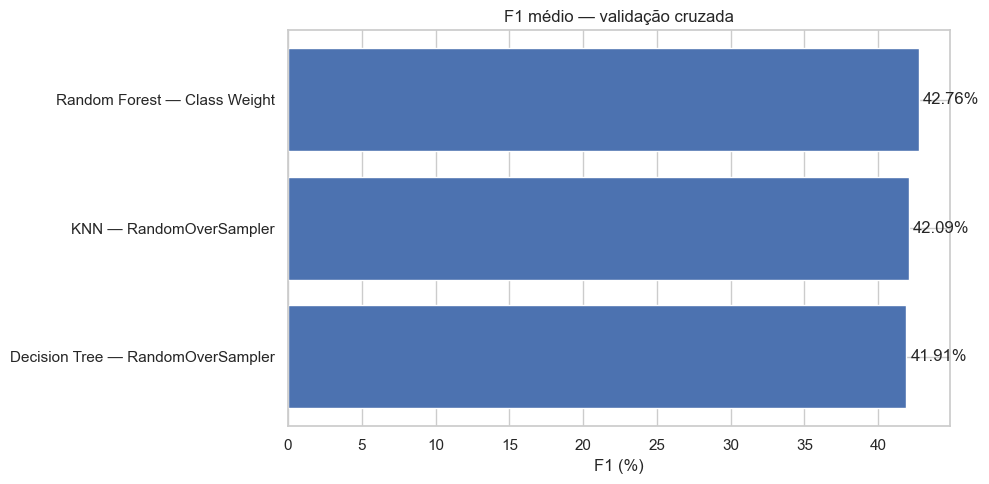

In [6]:
plot=resumo_cv.sort_values("F1_%"); fig,ax=plt.subplots(figsize=(10,5)); barras=ax.barh(plot["Modelo"],plot["F1_%"]); ax.set_title("F1 médio — validação cruzada"); ax.set_xlabel("F1 (%)"); ax.set_ylabel(""); ax.bar_label(barras,fmt="%.2f%%",padding=3); plt.tight_layout(); plt.savefig(FIGURES/"05_f1_validacao_cruzada.png",dpi=160,bbox_inches="tight"); plt.show()

**Interpretação.** A proximidade de F1 entre os finalistas impede uma escolha mecânica. A Random Forest é selecionada pelo conjunto de evidências: maior F1 e Precision entre os finalistas, menor quantidade de falsos positivos e maior ROC-AUC na análise completa.

In [7]:
melhor_modelo_cv=resumo_cv.iloc[0]; assert melhor_modelo_cv["Modelo"]=="Random Forest — Class Weight"
modelo_final=clone(modelos["Random Forest — Class Weight"]); modelo_final.fit(X_train,y_train)
caminho_modelo=MODELS/"modelo_final_random_forest_credito.joblib"; joblib.dump(modelo_final,caminho_modelo,compress=3)
print("Pipeline final salva localmente em:",caminho_modelo)
print("O arquivo .joblib é ignorado pelo Git; pode ser regenerado executando este notebook.")

Pipeline final salva localmente em: C:\Users\didan\Downloads\tech_challenge_fase2_grupo35_completo_com_dados\repositorio_github\results\models\modelo_final_random_forest_credito.joblib
O arquivo .joblib é ignorado pelo Git; pode ser regenerado executando este notebook.
